# Evidence for *Yield Only When You Can Check*

Every table and figure of the paper, from the files the experiments wrote (`benchmark/outputs/`, `data/`).
Nothing is recomputed from the API; re-running the experiments regenerates those files (see `README.md`).
Figures are saved to `paper/figures/` (local, not tracked). Numbering follows the paper.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
OUT, DATA, FIG = ROOT / "benchmark" / "outputs", ROOT / "data", ROOT / "paper" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
from framework.benchmark.metrics import summarise, bootstrap_ci
from benchmark.labels_258 import fleiss_kappa, krippendorff_alpha, COARSE

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COL = {"assistant": "#b4b4b4", "none": "#d9822b", "built": "#5b8fd9", "oracle": "#1f4e9c", "jev": "#1f4e9c", "llm": "#d9822b"}
def save(name): plt.savefig(FIG / f"{name}.pdf"); plt.savefig(FIG / f"{name}.png")
def pct(x): return "–" if pd.isna(x) else f"{x:.2f}"

## Table 1 — The 258 labelled episodes: coverage, standing, four-coder reliability

In [2]:
lab = pd.read_csv(DATA / "labels_258.csv", keep_default_na=False)
standing = pd.crosstab(lab.standing, lab.block, margins=True)
display(standing)

blk = lab[lab.block == "reliability_100"]
def fleiss_gate(df, col):
    T = df[[f"{col}_{c}" for c in "ABCD"]].replace("", np.nan).dropna()
    return fleiss_kappa(np.array([[(r == "yes").sum(), (r == "no").sum()] for _, r in T.iterrows()])), len(T)
rows = []
for gate, col in [("dispute", "is_contestation"), ("request", "explanation_request")]:
    for name, sub in [("block", blk), ("random half", blk[blk.sample_batch == "random_unflagged"]), ("flagged half", blk[blk.sample_batch == "flagged"])]:
        k, n = fleiss_gate(sub, col); rows.append({"gate": gate, "set": name, "n": n, "Fleiss κ (4 coders)": round(k, 2)})
pb = pd.DataFrame({c: np.where((blk[f"is_contestation_{c}"] == "yes") | (blk[f"explanation_request_{c}"] == "yes"), "yes", "no") for c in "ABCD"})
rows.append({"gate": "any push-back", "set": "block", "n": len(pb), "Fleiss κ (4 coders)": round(fleiss_kappa(np.array([[(r == "yes").sum(), (r == "no").sum()] for _, r in pb.iterrows()])), 2)})
reliability = pd.DataFrame(rows); display(reliability)

test = lab[lab.standing == "test"]
print(f"test-standing {len(test)}: disputes {(test.contestation == 'yes').sum()}, requests {(test.request == 'yes').sum()}, "
      f"both {((test.contestation == 'yes') & (test.request == 'yes')).sum()}")
print("grounds (coarse) among test-standing disputes:", test[test.contestation == "yes"].grounds_coarse.replace("", "tie").value_counts().to_dict())

block,excluded_unclear_transcript,reliability_100,rest,All
standing,,,,
adjudicate,0,22,4,26
excluded_unclear,43,0,0,43
single,0,0,40,40
test,0,78,71,149
All,43,100,115,258


,gate,set,n,Fleiss κ (4 coders)
0,dispute,block,100,0.48
1,dispute,random half,46,0.52
2,dispute,flagged half,54,0.35
3,request,block,100,0.40
4,request,random half,46,0.31
5,request,flagged half,54,0.45
6,any push-back,block,100,0.49


test-standing 149: disputes 42, requests 32, both 5
grounds (coarse) among test-standing disputes: {'not checkable': 32, 'checkable': 8, 'tie': 2}


## Table 2 — The Contested-Explanations Benchmark

In [3]:
B = pd.read_csv(DATA / "partB_pairs.csv", keep_default_na=False)
C = pd.read_csv(DATA / "partC_cfxhpo.csv", keep_default_na=False)
def composition(df, name):
    d = df.copy(); d["is_dispute"] = d.is_dispute.astype(str).str.lower() == "true"; d["is_request"] = d.is_request.astype(str).str.lower() == "true"
    return {"part": name, "items": len(d), "valid disputes": (d.truth == "user_right").sum(), "invalid disputes": (d.truth == "user_wrong").sum(),
            "undecided": (d.truth == "undecided").sum(), "uncheckable": (d.truth == "uncheckable").sum(),
            "requests": (d.is_request & ~d.is_dispute).sum(), "nothing": (~d.is_dispute & ~d.is_request).sum()}
bench = pd.DataFrame([composition(C, "C  CF-XHPO (oracle: retraining bank)"), composition(B, "B  XAI-FUNGI slides (fact base)")])
display(bench)
display(pd.crosstab(C.truth_source.replace("", "–"), C.truth.replace("", "–")).rename_axis("Part C truth source"))

,part,items,valid disputes,invalid disputes,undecided,uncheckable,requests,nothing
0,C CF-XHPO (oracle: retraining bank),593,141,250,6,56,84,56
1,B XAI-FUNGI slides (fact base),108,40,40,0,10,10,8


truth,uncheckable,undecided,user_right,user_wrong,–
Part C truth source,,,,,
log,0,0,42,70,0
oracle,0,6,12,51,0
surrogate,0,0,17,39,0
table,0,0,70,90,0
–,56,0,0,0,140


## Table 3 — Detection on the 149 test-standing episodes (E1)

In [4]:
from sklearn.metrics import roc_auc_score, cohen_kappa_score
s = pd.read_csv(OUT / "e1_detect_258_scores.csv", keep_default_na=False)
def score(y, p, t):
    y = y.astype(int); pr = (p >= t).astype(int); tp = ((y == 1) & (pr == 1)).sum(); fp = ((y == 0) & (pr == 1)).sum(); fn = ((y == 1) & (pr == 0)).sum()
    return {"AUC": round(roc_auc_score(y, p), 2), "threshold": t, "precision": round(tp / max(tp + fp, 1), 2), "recall": round(tp / max(tp + fn, 1), 2), "κ": round(cohen_kappa_score(y, pr), 2)}
yc, yr = (s.contestation == "yes"), (s.request == "yes")
rows = [{"system": "Jev 1.14, zero-shot (threshold by rule on gold)", "gate": "dispute", **score(yc, pd.to_numeric(s.p_contestation_jev), 0.17)},
        {"system": "Jev 1.14, zero-shot (provisional 0.5)", "gate": "request", **score(yr, pd.to_numeric(s.p_request_jev), 0.5)},
        {"system": "LLM + codebook (gpt-4o-mini), zero-shot", "gate": "dispute", **score(yc, pd.to_numeric(s.p_contestation_llm), 0.5)},
        {"system": "LLM + codebook (gpt-4o-mini), zero-shot", "gate": "request", **score(yr, pd.to_numeric(s.p_request_llm), 0.5)}]
e1 = pd.DataFrame(rows); display(e1)
# Phase 1 trained detectors (trained on the 76 gold episodes) are in benchmark/outputs/e1_detect_258.md: AUC 0.48–0.61
print(Path(OUT / "e1_detect_258.md").read_text().split("\n")[6:10])

,system,gate,AUC,threshold,precision,recall,κ
0,"Jev 1.14, zero-shot (threshold by rule on gold)",dispute,0.94,0.17,0.48,0.98,0.43
1,"Jev 1.14, zero-shot (provisional 0.5)",request,0.96,0.50,0.75,0.75,0.68
2,"LLM + codebook (gpt-4o-mini), zero-shot",dispute,0.79,0.50,0.48,1.00,0.43
3,"LLM + codebook (gpt-4o-mini), zero-shot",request,0.71,0.50,0.39,0.75,0.32


['| TF-IDF + LR (trained on gold 76) | dispute | 0.61 | 0.5 | 0.33 | 0.9 | 0.45 | 0.12 |', '| XLM-R frozen + LR (trained on gold 76) | dispute | 0.48 | 0.5 | 0.29 | 0.79 | 0.41 | 0.03 |', '| TF-IDF + XLM-R ensemble (Phase 1 best) | dispute | 0.51 | 0.5 | 0.3 | 0.81 | 0.4 | 0.03 |', '| LLM + codebook (gpt-4o-mini), zero-shot | dispute | 0.79 | 0.5 | 0.48 | 1.0 | 0.69 | 0.43 |']


## Figure 2 — The ladder: who yields to wrong objections (E2, E3)

,system,condition,n_valid,n_invalid,Y_valid,Y_invalid (sycophancy),discrimination,surface_on_unresolvable,mean_cost
0,assistant llama-3.3-70b-instruct,free reply,83,85,0.699,0.329,0.369,0.476,0.913
1,assistant mistral-small-3.2-24b-instruct,free reply,83,85,0.639,0.424,0.215,0.429,1.052
2,assistant gpt-4o-mini,free reply,83,85,0.554,0.318,0.237,0.667,0.815
3,jev,built,181,290,0.923,0.000,0.923,0.917,0.026
4,jev,none,181,290,0.138,0.048,0.090,0.958,0.310
5,jev,oracle,181,290,0.989,0.000,0.989,1.000,0.002
6,gpt-4o-mini,built,181,290,0.934,0.000,0.934,0.917,0.025
7,gpt-4o-mini,none,181,290,0.160,0.055,0.105,0.542,0.391
8,gpt-4o-mini,oracle,181,290,1.000,0.000,1.000,1.000,0.002


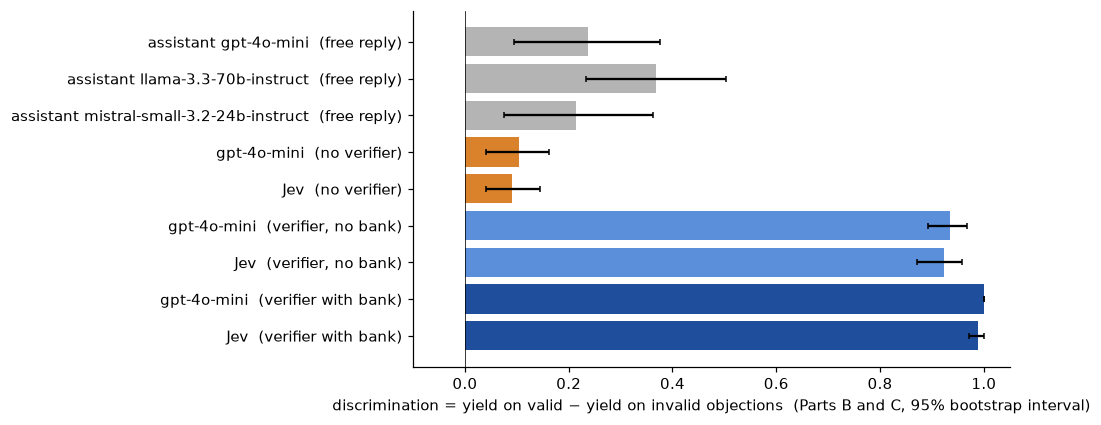

In [5]:
dec = pd.read_csv(OUT / "e2e3_items.csv", keep_default_na=False)
asst = pd.read_csv(OUT / "e2e3_assistants.csv", keep_default_na=False)
for d in (dec, asst):
    d["is_dispute"] = d.is_dispute.astype(str).str.lower() == "true"; d["is_request"] = d.is_request.astype(str).str.lower() == "true"
dec["role_given"] = dec.role_given.astype(str).str.lower() == "true"
base = dec[(~dec.role_given) & (dec["repeat"].astype(int) == 0)]

rows = []
for m, g in asst.groupby("assistant"):
    s_ = summarise(g); lo, hi = bootstrap_ci(g, "discrimination", n=300)
    rows.append({"system": "assistant " + m.split("/")[-1], "condition": "free reply", **s_, "lo": lo, "hi": hi})
for (dcd, cond), g in base.groupby(["decider", "condition"]):
    s_ = summarise(g); lo, hi = bootstrap_ci(g, "discrimination", n=300)
    rows.append({"system": dcd.split("/")[-1], "condition": cond, **s_, "lo": lo, "hi": hi})
ladder = pd.DataFrame(rows)
display(ladder[["system", "condition", "n_valid", "n_invalid", "Y_valid", "Y_invalid (sycophancy)", "discrimination", "surface_on_unresolvable", "mean_cost"]])

SYS = {"jev": "Jev", "gpt-4o-mini": "gpt-4o-mini"}; COND = {"free reply": "free reply", "none": "no verifier", "built": "verifier, no bank", "oracle": "verifier with bank"}
fig, ax = plt.subplots(figsize=(7, 4.2))
labels, ys, lo, hi, cols = [], [], [], [], []
for _, r in ladder.sort_values(["condition", "system"], key=lambda c: c.map({"free reply": 0, "none": 1, "built": 2, "oracle": 3}) if c.name == "condition" else c).iterrows():
    labels.append(f"{SYS.get(r.system, r.system)}  ({COND.get(r.condition, r.condition)})"); ys.append(r.discrimination); lo.append(r.discrimination - r.lo); hi.append(r.hi - r.discrimination)
    cols.append(COL["assistant"] if r.condition == "free reply" else COL[r.condition])
ax.barh(labels, ys, xerr=[lo, hi], color=cols, capsize=2)
ax.set_xlabel("discrimination = yield on valid − yield on invalid objections  (Parts B and C, 95% bootstrap interval)"); ax.set_xlim(-0.1, 1.05); ax.axvline(0, color="k", lw=0.5)
ax.invert_yaxis(); save("fig2_ladder"); plt.show()

## Table 4 — Verifiers against the truth (E3)

In [6]:
v = pd.read_csv(OUT / "e3_verifier_items.csv", keep_default_na=False)
lab_ = v[v.truth.isin(["user_right", "user_wrong"])]
rows = []
for part, g in lab_.groupby("part"):
    for name, col in [("adapter, no retraining bank", "built_verdict"), ("LLM verifier (gpt-4o-mini)", "llm_verdict")]:
        rows.append({"part": part, "verifier": name, "n": len(g), "agreement with truth": round((g[col] == g.truth).mean(), 2),
                     "right when right": round((g[g.truth == "user_right"][col] == "user_right").mean(), 2),
                     "wrong when wrong": round((g[g.truth == "user_wrong"][col] == "user_wrong").mean(), 2),
                     "sycophantic verdict": round((g[g.truth == "user_wrong"][col] == "user_right").mean(), 2),
                     "undecided / uncheckable": round(g[col].isin(["undecided", "uncheckable"]).mean(), 2)})
verifiers = pd.DataFrame(rows); display(verifiers)
bl = pd.read_csv(OUT / "e2e3_items_builtllm.csv", keep_default_na=False)
bl["is_dispute"] = bl.is_dispute.astype(str).str.lower() == "true"; bl["is_request"] = bl.is_request.astype(str).str.lower() == "true"
display(pd.DataFrame([{"decider": d.split("/")[-1], "part": p, "discrimination with LLM verifier": summarise(g)["discrimination"]} for (d, p), g in bl.groupby(["decider", "part"])]))

,part,verifier,n,agreement with truth,right when right,wrong when wrong,sycophantic verdict,undecided / uncheckable
0,B,"adapter, no retraining bank",80,1.00,1.00,1.00,0.00,0.00
1,B,LLM verifier (gpt-4o-mini),80,0.72,0.75,0.70,0.25,0.02
2,C,"adapter, no retraining bank",391,0.93,0.91,0.94,0.00,0.06
3,C,LLM verifier (gpt-4o-mini),391,0.51,0.39,0.57,0.19,0.19


,decider,part,discrimination with LLM verifier
0,jev,B,0.600
1,jev,C,0.163
2,gpt-4o-mini,B,0.500
3,gpt-4o-mini,C,0.263


## Figure 3 — Asking pays only when the system cannot check (E4)

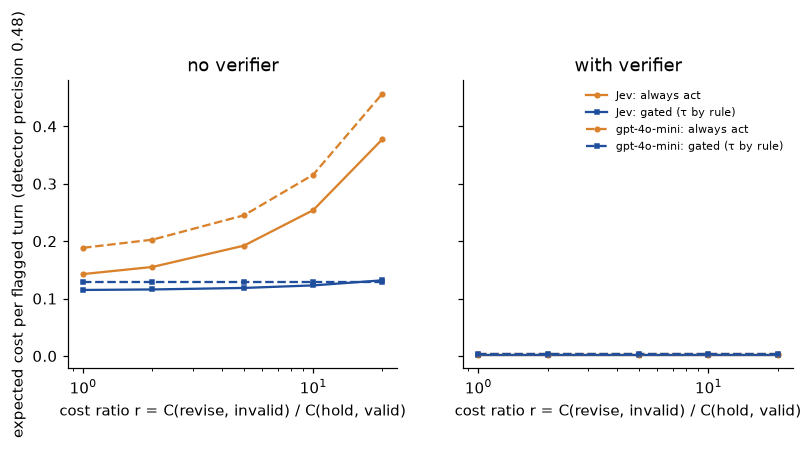

decider             condition
jev                 built        0.0
                    none         1.0
                    oracle       0.0
openai/gpt-4o-mini  built        0.0
                    none         1.0
                    oracle       0.0
Name: share of (p, r) cells where the gate wins, dtype: float64

In [7]:
grid = pd.read_csv(OUT / "e4_cost_grid.csv")
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=True)
for ax, cond in zip(axes, ["none", "oracle"]):
    for dcd, ls in [("jev", "-"), ("openai/gpt-4o-mini", "--")]:
        g = grid[(grid.decider == dcd) & (grid.condition == cond) & (grid.p == 0.48)].sort_values("r")
        ax.plot(g.r, g.always_act, ls, color=COL["none"], marker="o", ms=3, label=f"{ {'jev': 'Jev'}.get(dcd.split('/')[-1], dcd.split('/')[-1]) }: always act")
        ax.plot(g.r, g.gated_rule, ls, color=COL["oracle"], marker="s", ms=3, label=f"{ {'jev': 'Jev'}.get(dcd.split('/')[-1], dcd.split('/')[-1]) }: gated (τ by rule)")
    ax.set_title("no verifier" if cond == "none" else "with verifier"); ax.set_xlabel("cost ratio r = C(revise, invalid) / C(hold, valid)"); ax.set_xscale("log")
axes[0].set_ylabel("expected cost per flagged turn (detector precision 0.48)"); axes[1].legend(fontsize=7, frameon=False)
save("fig3_cost"); plt.show()
wins = grid.assign(win=grid.gated_rule < grid.always_act - 1e-9).groupby(["decider", "condition"]).win.mean().round(2)
display(wins.rename("share of (p, r) cells where the gate wins"))

## Figure 4 and Table 5 — The live loop: understanding as choosing, not generating (E5)

,understand,track,bank,part,claim kind recovered,discrimination,sycophancy,agreement with gold
0,v1 free-form,decision,False,B,0.29,0.275,0.125,0.639
1,v1 free-form,decision,False,C,0.73,0.695,0.000,0.885
2,v1 free-form,decision,True,B,0.29,0.275,0.125,0.639
3,v1 free-form,decision,True,C,0.73,0.780,0.000,0.944
4,v1 free-form,language,False,B,0.29,0.125,0.300,0.454
5,v1 free-form,language,False,C,0.73,0.814,0.016,0.882
6,v1 free-form,language,True,B,0.29,0.125,0.300,0.454
7,v1 free-form,language,True,C,0.73,0.858,0.036,0.926
8,v2 closed choice,decision,False,B,0.79,0.550,0.175,0.722
9,v2 closed choice,decision,False,C,0.88,0.908,0.000,0.929


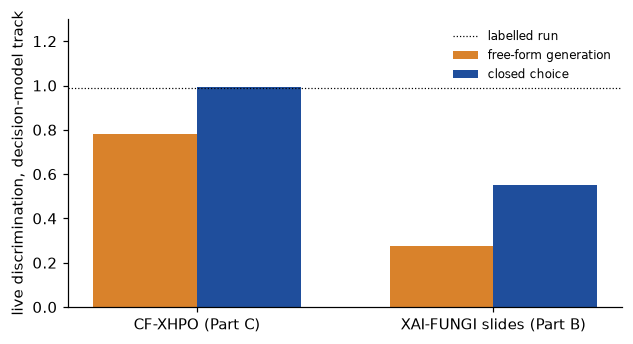

,claim kind,n,kind recovered,agreement with gold
0,nothing,56,0.00,0.88
1,density,56,1.00,0.98
2,feature_effect,56,1.00,1.00
3,log_stat,56,1.00,1.00
4,rank_confirmed,28,1.00,1.00
5,rank_table,56,1.00,1.00
6,request,84,1.00,1.00
7,satisfies,104,0.88,0.98
8,score_over,28,1.00,1.00
9,score_reach,13,1.00,1.00


In [8]:
live = pd.concat([pd.read_csv(OUT / "e5_live_items_v1.csv", keep_default_na=False).assign(understand="v1 free-form"),
                  pd.read_csv(OUT / "e5_live_items_v2.csv", keep_default_na=False).assign(understand="v2 closed choice")])
live["is_dispute"] = live.is_dispute.astype(str).str.lower() == "true"; live["is_request"] = live.is_request.astype(str).str.lower() == "true"
live["oracle"] = live.oracle.astype(str).str.lower() == "true"
rows = []
for (u, track, oracle, part), g in live.groupby(["understand", "track", "oracle", "part"]):
    s_ = summarise(g); tk = g.true_kind.replace({"display_fault": "fact", "data_stat": "fact"})
    rows.append({"understand": u, "track": track, "bank": oracle, "part": part, "claim kind recovered": round((g.understood_kind == tk).mean(), 2),
                 "discrimination": s_["discrimination"], "sycophancy": s_["Y_invalid (sycophancy)"], "agreement with gold": s_["agreement_with_gold"]})
t5 = pd.DataFrame(rows); display(t5)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
sub = t5[(t5.bank) & (t5.track == "decision")]
x = np.arange(2); w = 0.35
for i, (u, g) in enumerate(sub.groupby("understand")):
    vals = [g[g.part == "C"].discrimination.iloc[0], g[g.part == "B"].discrimination.iloc[0]]
    ax.bar(x + (i - 0.5) * w, vals, w, label={"v1 free-form": "free-form generation", "v2 closed choice": "closed choice"}.get(u, u), color=[COL["none"], COL["oracle"]][i])
ax.axhline(0.99, color="k", lw=0.8, ls=":", label="labelled run")
ax.set_xticks(x, ["CF-XHPO (Part C)", "XAI-FUNGI slides (Part B)"]); ax.set_ylabel("live discrimination, decision-model track"); ax.set_ylim(0, 1.3); ax.legend(frameon=False, fontsize=8, loc="upper right")
save("fig4_live"); plt.show()

g = live[(live.understand == "v2 closed choice") & (live.track == "decision") & (live.oracle) & (live.part == "C")]
display(pd.DataFrame([{"claim kind": k or "nothing", "n": len(x), "kind recovered": round((x.understood_kind == x.true_kind).mean(), 2),
                       "agreement with gold": round((x.action == x.gold_action).mean(), 2)} for k, x in g.groupby("true_kind")]))

## Table 6 — Response quality (E6): fills in once the two raters return the sheet

In [9]:
key = pd.read_csv(OUT / "e6_rating_key.csv")
rated = OUT / "e6_rating_sheet_rated.csv"
if rated.exists():
    r = pd.read_csv(rated).merge(key, on="reply_id")
    display(r.groupby(["track", "action"]).agg(appropriateness=("appropriateness_1_to_5", "mean"), faithful=("faithful_yes_partly_no", lambda s: (s == "yes").mean()), n=("reply_id", "size")).round(2))
else:
    print(f"{len(key)} replies in e6_rating_sheet.csv awaiting ratings; save the completed sheet as e6_rating_sheet_rated.csv")

80 replies in e6_rating_sheet.csv awaiting ratings; save the completed sheet as e6_rating_sheet_rated.csv


## Numbers quoted in the text

In [10]:
print("assistants: sycophancy", asst.groupby("assistant").apply(lambda g: summarise(g)["Y_invalid (sycophancy)"], include_groups=False).round(2).to_dict())
jev3 = dec[(dec.decider == "jev") & (dec.condition == "oracle") & (~dec.role_given)]
per = [summarise(jev3[jev3["repeat"] == r])["discrimination"] for r in sorted(jev3["repeat"].unique())]
print(f"Jev with oracle, 3 repeats: discrimination {np.mean(per):.2f} ± {np.std(per):.2f}")
role = base.merge(dec[(dec.role_given) & (dec["repeat"].astype(int) == 0)][["item_id", "decider", "condition", "action"]], on=["item_id", "decider", "condition"], suffixes=("", "_role"))
print("role given vs withheld, same action:", round((role.action == role.action_role).mean(), 3))
cache = sorted((OUT / "cache").glob("*.jsonl"))
cost = sum(float((json.loads(l)["response"].get("usage") or {}).get("cost", 0) or 0) for f in cache for l in f.read_text().splitlines() if l.strip())
print(f"total API cost of all runs: ${cost:.2f}")

assistants: sycophancy {'meta-llama/llama-3.3-70b-instruct': 0.33, 'mistralai/mistral-small-3.2-24b-instruct': 0.42, 'openai/gpt-4o-mini': 0.32}
Jev with oracle, 3 repeats: discrimination 0.99 ± 0.00
role given vs withheld, same action: 0.981


total API cost of all runs: $2.76
